In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [5]:
df = pd.read_csv("C://Users//Admin//Downloads//House-price-prediction-dataset//housing.csv")
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [6]:
df.shape

(20640, 10)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [8]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [9]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.nunique()

longitude               844
latitude                862
housing_median_age       52
total_rooms            5926
total_bedrooms         1923
population             3888
households             1815
median_income         12928
median_house_value     3842
ocean_proximity           5
dtype: int64

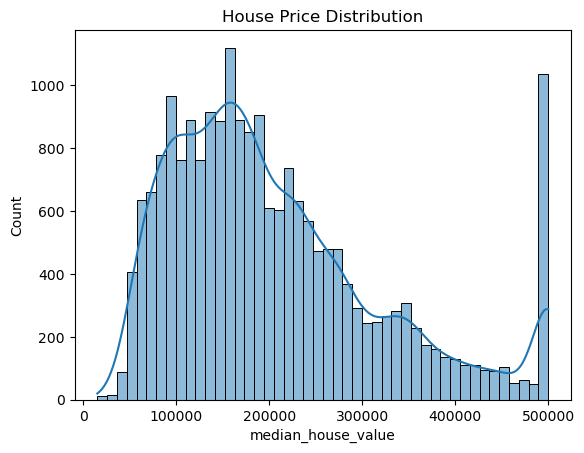

In [12]:
sns.histplot(df["median_house_value"], kde=True)
plt.title("House Price Distribution")
plt.show()

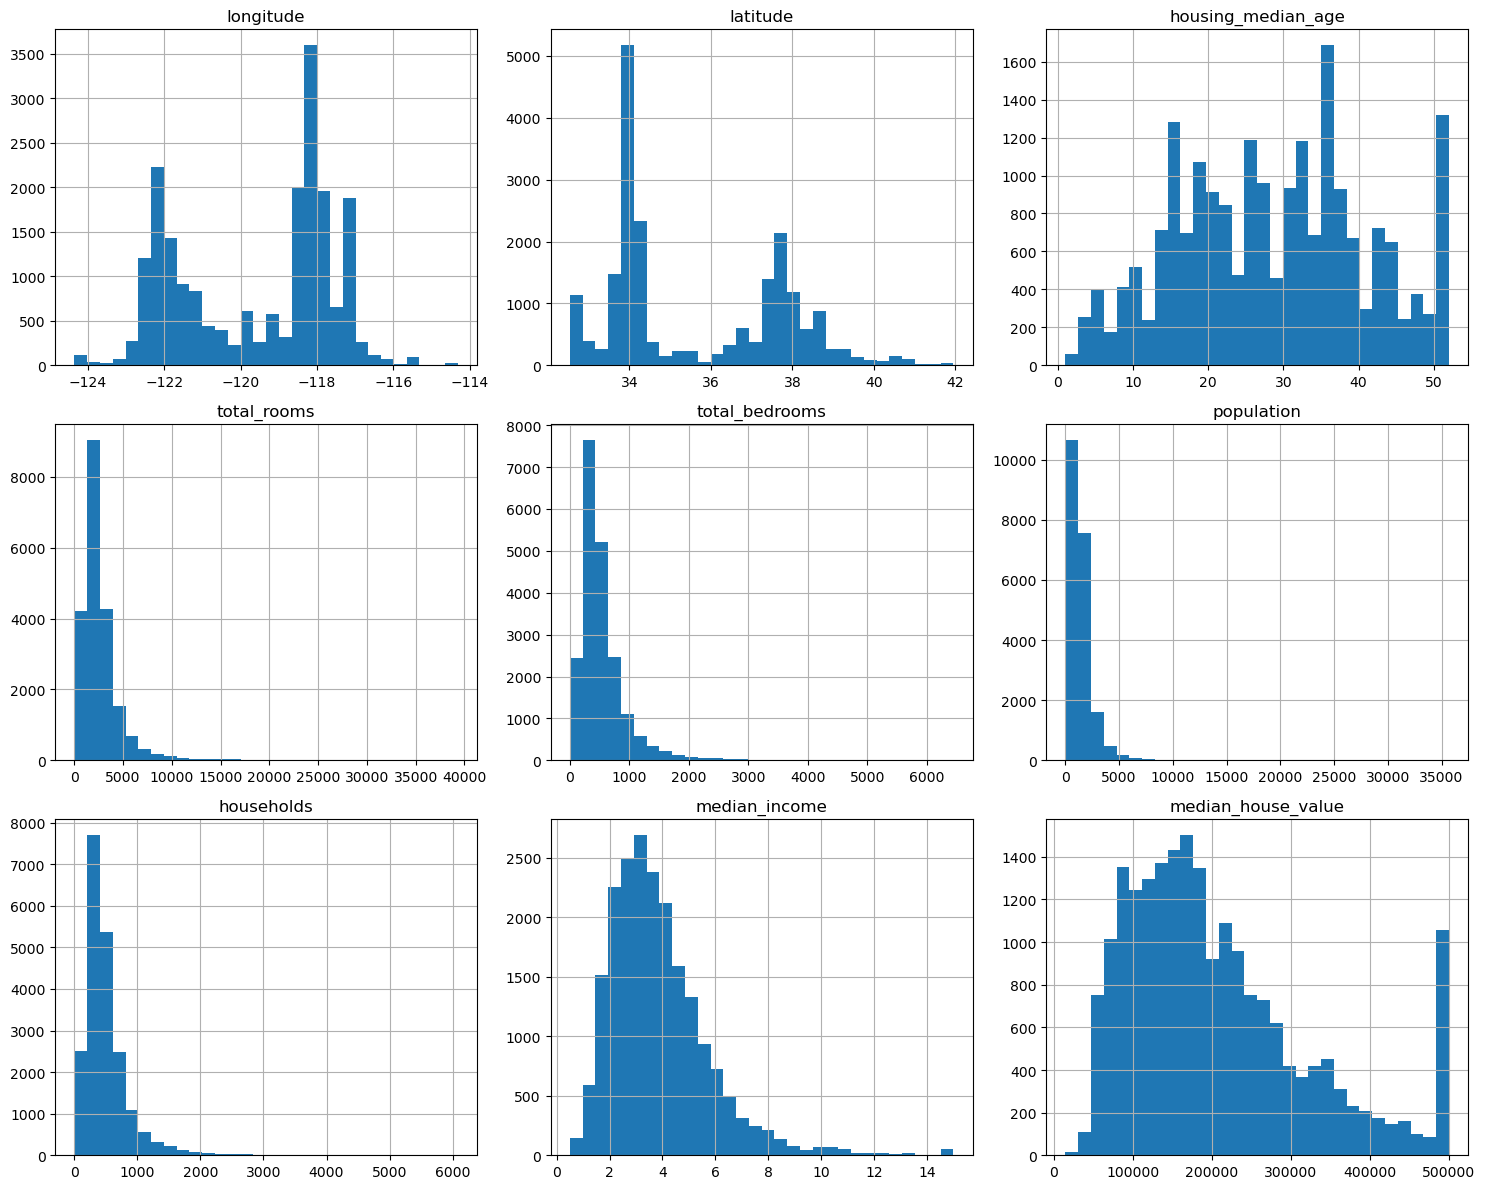

In [13]:
num_cols = df.select_dtypes(include=np.number).columns
df[num_cols].hist(figsize=(15,12), bins = 30)
plt.tight_layout()
plt.show()

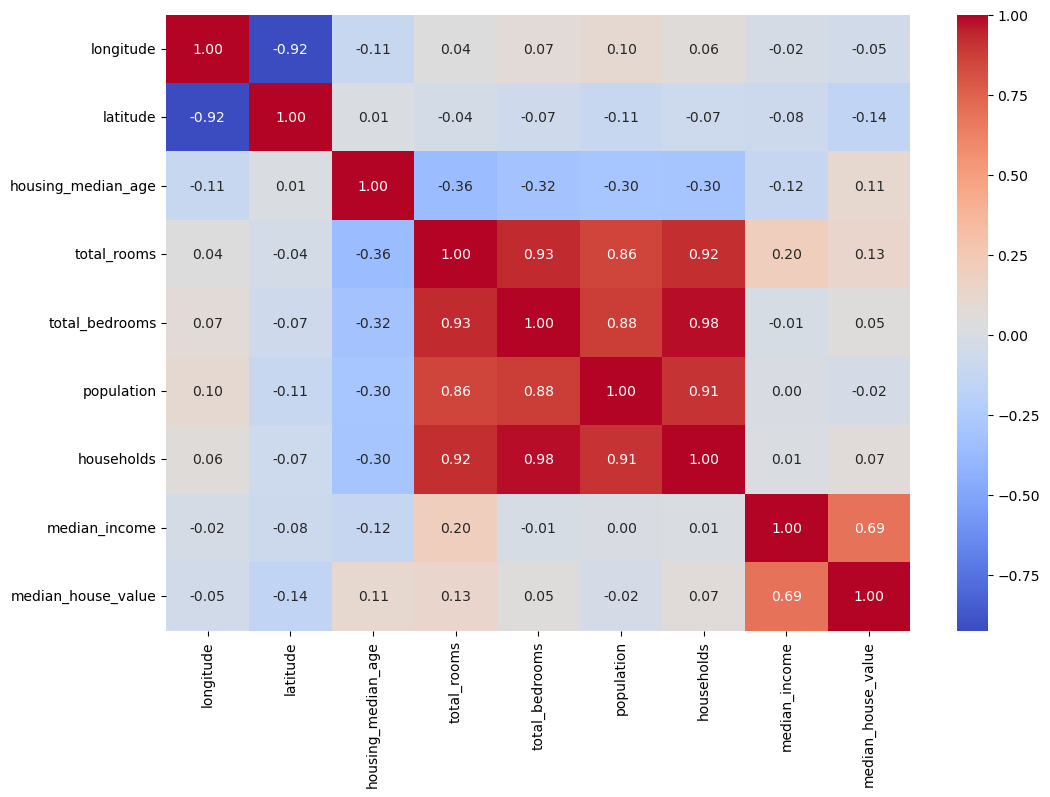

In [14]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    df[num_cols].corr(),
    annot = True, 
    cmap="coolwarm",
    fmt=".2f"
)
plt.show()

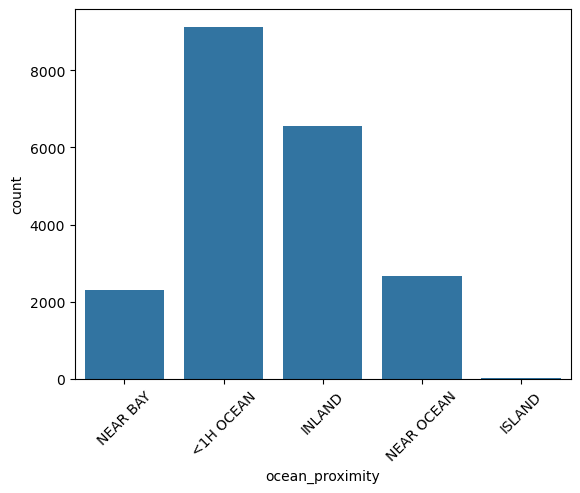

In [15]:
sns.countplot(data = df, x="ocean_proximity")
plt.xticks(rotation=45)
plt.show()

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df["total_bedrooms"].describe()

count    20433.000000
mean       537.870553
std        421.385070
min          1.000000
25%        296.000000
50%        435.000000
75%        647.000000
max       6445.000000
Name: total_bedrooms, dtype: float64

In [18]:
Q1 = df["total_bedrooms"].quantile(0.25)
Q3 = df["total_bedrooms"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower Bound:", lower)
print("Upper Bound:", upper)

outliers = df[
    (df["total_bedrooms"] <lower) | (df["total_bedrooms"] > upper)
    ]
print("Number of Outliers:", len(outliers))

Lower Bound: -230.5
Upper Bound: 1173.5
Number of Outliers: 1271


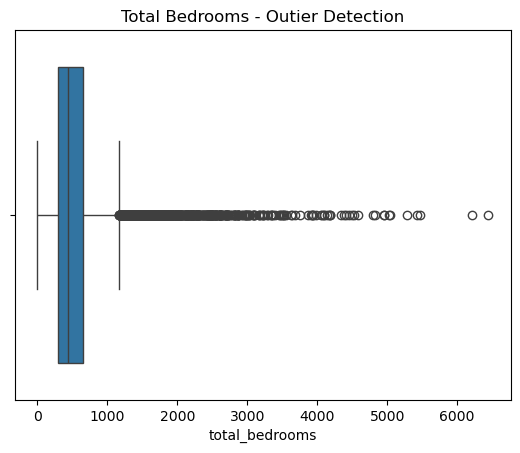

In [19]:
sns.boxplot(x=df["total_bedrooms"])
plt.title("Total Bedrooms - Outier Detection")
plt.show()

In [20]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [21]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage)

longitude             0.000000
latitude              0.000000
housing_median_age    0.000000
total_rooms           0.000000
total_bedrooms        1.002907
population            0.000000
households            0.000000
median_income         0.000000
median_house_value    0.000000
ocean_proximity       0.000000
dtype: float64


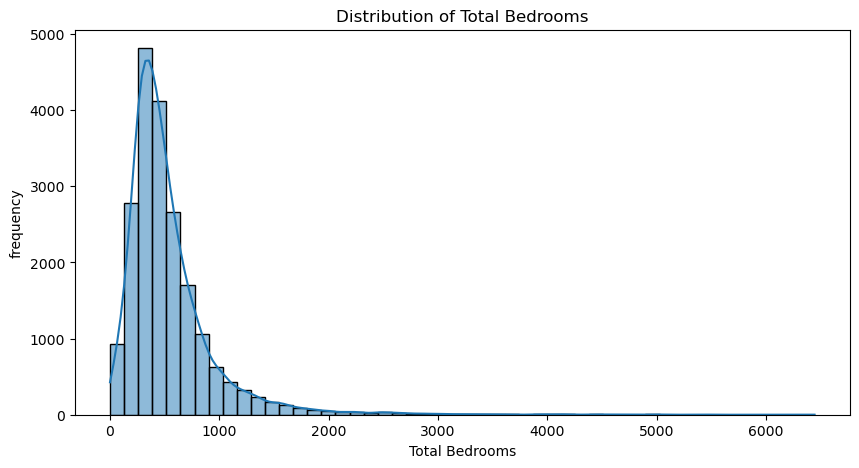

In [22]:
plt.figure(figsize = (10,5))
sns.histplot(df["total_bedrooms"], bins=50, kde=True)
plt.title("Distribution of Total Bedrooms")
plt.xlabel("Total Bedrooms")
plt.ylabel("frequency")
plt.show()

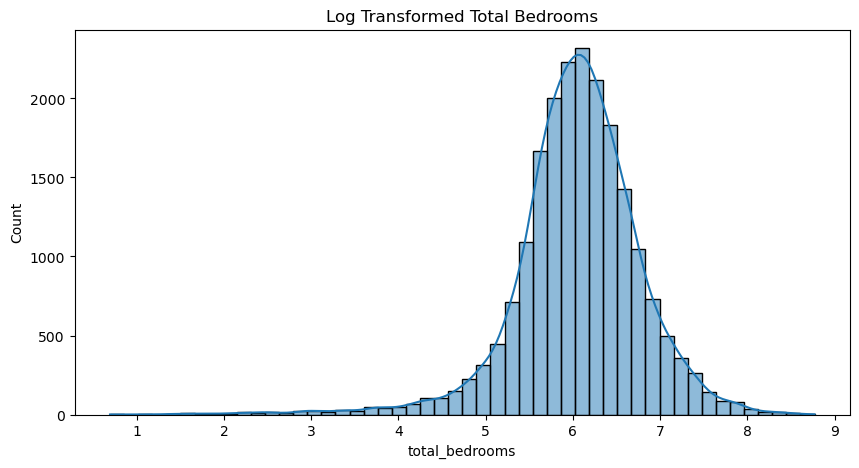

In [23]:
plt.figure(figsize=(10,5))
sns.histplot(np.log1p(df["total_bedrooms"]), bins=50, kde=True)
plt.title("Log Transformed Total Bedrooms")
plt.show()

In [24]:
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]
    print(col, ":", len(outliers))

longitude : 0
latitude : 0
housing_median_age : 0
total_rooms : 1287
total_bedrooms : 1271
population : 1196
households : 1220
median_income : 681
median_house_value : 1071


In [25]:
df["rooms_per_household"] = (
    df["total_rooms"] / df["households"]
)

df["bedrooms_per_room"] = (
    df["total_bedrooms"] / df["total_rooms"]
)

df["population_per_household"] = (
    df["population"] / df["households"]
)

In [26]:
X = df.drop("median_house_value", axis = 1)
y = df["median_house_value"]

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y,
    test_size = 0.2,
    random_state = 42
)
print(X_train.shape)
print(X_test.shape)

(16512, 12)
(4128, 12)


In [28]:
num_features = X_train.select_dtypes(
    include = np.number
).columns
cat_features = X_train.select_dtypes(
    exclude = np.number
).columns

In [29]:
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler())
])

In [30]:
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy = "most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown = "ignore"))
])

In [31]:
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_features),
    ("cat", cat_pipeline, cat_features)
])

In [32]:
def evaluate_model(model, X_train, X_test, y_train, y_test):

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    print("Training R2:", r2_score(y_train, train_pred))
    print("Testing R2:", r2_score(y_test, test_pred))

    print("Training RMSE:",
          np.sqrt(mean_squared_error(y_train, train_pred)))

    print("Testing RMSE:",
          np.sqrt(mean_squared_error(y_test, test_pred)))

    print("Testing MAE:",
          mean_absolute_error(y_test, test_pred))

In [33]:
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

evaluate_model(
    linear_model,
    X_train,
    X_test,
    y_train,
    y_test
)

Training R2: 0.6582199160539229
Testing R2: 0.6353392335238193
Training RMSE: 67593.20745775253
Testing RMSE: 69127.03829924983
Testing MAE: 49645.49244453642


In [34]:
ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])
evaluate_model(
    ridge_model,
    X_train,
    X_test,
    y_train, 
    y_test
)

Training R2: 0.658209973961378
Testing R2: 0.6352555955611365
Training RMSE: 67594.19056511964
Testing RMSE: 69134.9652737178
Testing MAE: 49652.14287272515


In [35]:
ridge_params = {
    "model__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}
ridge_grid = GridSearchCV(
    ridge_model,
    ridge_params,
    cv=5,
    scoring="r2",
    n_jobs =-1
)
ridge_grid.fit(X_train, y_train)
print(ridge_grid.best_params_)
print(ridge_grid.best_score_)

{'model__alpha': 1}
0.6554640934284983


In [36]:
lasso_model = Pipeline([
    ("Preprocessor", preprocessor),
    ("model", Lasso(alpha=0.1, max_iter=20000))
])
evaluate_model(
    lasso_model,
    X_train,
    X_test,
    y_train,
    y_test
)

Training R2: 0.6582199129022669
Testing R2: 0.6353381679353018
Training RMSE: 67593.2077694011
Testing RMSE: 69127.13929849518
Testing MAE: 49645.58411589987


C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.268e+12, tolerance: 2.207e+10
  model = cd_fast.enet_coordinate_descent(


In [46]:
lasso_params = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100]
}
lasso_grid = GridSearchCV(
    lasso_model,
    lasso_params,
    cv=5,
    scoring="r2",
    n_jobs =-1
)
lasso_grid.fit(X_train, y_train)
print(lasso_grid.best_params_)
print(lasso_grid.best_score_)

{'model__alpha': 1}
0.6554521795017643


In [45]:
elastic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", ElasticNet(max_iter=20000))
])
elastic_params = {
    "model__alpha":[0.001, 0.01, 0.1, 1, 10],
    "model__l1_ratio":[0.1, 0.3, 0.5, 0.7, 0.9]
}
elastic_grid = GridSearchCV(
    elastic_model,
    elastic_params,
    cv=5,
    scoring="r2",
    n_jobs=-1
)
elastic_grid.fit(X_train, y_train)

print(elastic_grid.best_params_)
print(elastic_grid.best_score_)
print(elastic_grid.best_estimator_)

{'model__alpha': 0.001, 'model__l1_ratio': 0.9}
0.6554629935003173
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'rooms_per_household', 'bedrooms_per_room', 'population_per_household'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   Sim

In [42]:
elastic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", ElasticNet(max_iter=20000))
])
elastic_params = {
    "model__alpha":[0.001, 0.01, 0.1, 1, 10],
    "model__l1_ratio":[0.1, 0.3, 0.5, 0.7, 0.9]
}
elastic_grid = GridSearchCV(
    elastic_model,
    elastic_params,
    cv=5,
    scoring="r2",
    n_jobs=-1
)


{'model__alpha': 0.001, 'model__l1_ratio': 0.9}
0.6554629935003173
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'rooms_per_household', 'bedrooms_per_room', 'population_per_household'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   Sim

In [41]:
models = {
    "Linear Regression": linear_model,
    "Ridge": ridge_grid.best_estimator_,
    "Lasso": lasso_grid.best_estimator_,
    "Elastic Net": elastic_grid.best_estimator_
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred),
        "Train RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "Test MAE": mean_absolute_error(y_test, test_pred)
    })

results_df = pd.DataFrame(results)

results_df

,Model,Train R2,Test R2,Train RMSE,Test RMSE,Test MAE
0,Linear Regression,0.658220,0.635339,67593.207458,69127.038299,49645.492445
1,Ridge,0.658210,0.635256,67594.190565,69134.965274,49652.142873
2,Lasso,0.658220,0.635328,67593.238604,69128.091241,49646.428893
3,Elastic Net,0.658198,0.635207,67595.391835,69139.554407,49655.255759


In [53]:
for _, row in results_df.iterrows():

    train_score = row["Train R2"]
    test_score = row["Test R2"]

    gap = train_score - test_score

    print("\nModel:", row["Model"])
    print("Train R2:", train_score)
    print("Test R2:", test_score)
    print("Gap:", gap)

    if train_score < 0.5 and test_score < 0.5:
        print("Possible Underfitting")

    elif gap > 0.10:
        print("Possible Overfitting")

    else:
        print("No strong evidence of overfitting")


Model: Linear Regression
Train R2: 0.6582199160539229
Test R2: 0.6353392335238193
Gap: 0.02288068253010367
No strong evidence of overfitting

Model: Ridge
Train R2: 0.658209973961378
Test R2: 0.6352555955611365
Gap: 0.022954378400241504
No strong evidence of overfitting

Model: Lasso
Train R2: 0.6582196010770419
Test R2: 0.6353281244301747
Gap: 0.022891476646867193
No strong evidence of overfitting

Model: Elastic Net
Train R2: 0.658197825414331
Test R2: 0.6352071709713114
Gap: 0.02299065444301962
No strong evidence of overfitting


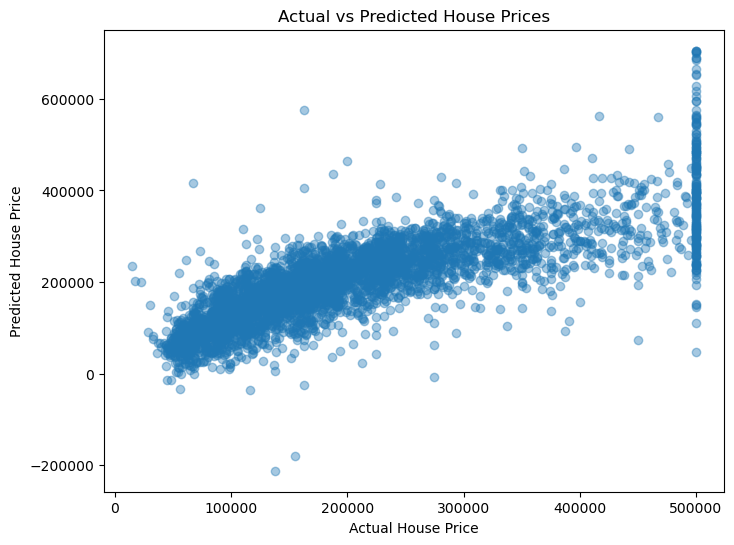

In [51]:
best_model = ridge_grid.best_estimator_

y_pred = best_model.predict(X_test)

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")

plt.title("Actual vs Predicted House Prices")

plt.show()

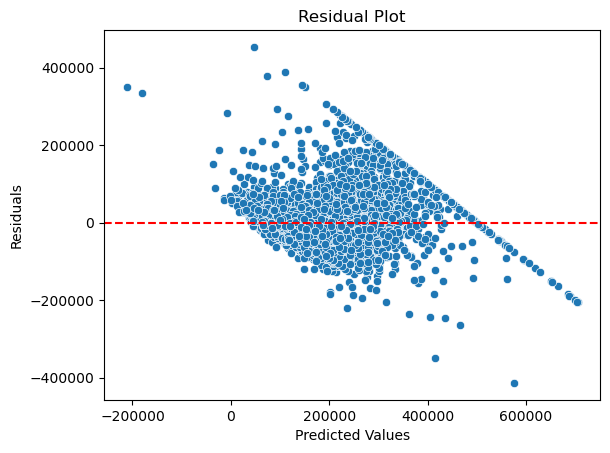

In [52]:
residuals = y_test - y_pred

sns.scatterplot(x=y_pred, y=residuals)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.show()